In [1]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Pandas version: 3.0.6
NumPy version: 2.3.4


In [9]:
# Dataset file in the same folder as your notebook
file_path = Path(
    r"C:\Users\ARYAN KATAKDHOND\Downloads\archive\reviews_500-750.csv"
)
if not file_path.exists():
    raise FileNotFoundError(
        "CSV not found. Place reviews_500-750.csv "
        "in the same folder as this notebook."
    )

# Preserve the original data
raw_df = pd.read_csv(file_path, low_memory=False)

# Create a separate working copy for cleaning
df = raw_df.copy(deep=True)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 116262
Columns: 19


In [10]:

# STEP 3: Initial Dataset Inspection

print("Dataset shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (116262, 19)

First 5 records:


,Unnamed: 0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,2079014373,5,1.0,NaN,0,0,0,2023-03-14,These are the only pimple patches I’ve used th...,Best Pimple Patches,medium,blue,normal,NaN,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0
1,1,12631885517,4,1.0,NaN,0,0,0,2023-02-08,One of my ingrown hair turned inflamed and sor...,It works!,mediumTan,brown,combination,black,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0
2,2,2321761961,5,1.0,1.0,1,0,1,2023-02-05,I have tried 10 different acne/blemish patches...,Good for a large or painful breakout! Sleep in...,NaN,hazel,combination,blonde,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0
3,3,1380382883,4,1.0,NaN,0,0,0,2023-01-24,"Love these for my mid-size breakouts, specifyi...",Micro tips are a plus!!,light,brown,combination,black,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0
4,4,8871759068,4,1.0,1.0,1,0,1,2023-01-15,Best so far - though still not particularly ef...,NaN,NaN,NaN,NaN,NaN,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0



Column names:
['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 116262 entries, 0 to 116261
Data columns (total 19 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                116262 non-null  int64  
 1   author_id                 116262 non-null  str    
 2   rating                    116262 non-null  int64  
 3   is_recommended            104459 non-null  float64
 4   helpfulness               59838 non-null   float64
 5   total_feedback_count      116262 non-null  int64  
 6   total_neg_feedback_count  116262 non-null  int64  
 7   total_pos_feedback_count  116262 non-null  

In [11]:
# STEP 4: Data Quality Assessment

# Create a summary of each column
quality_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True)
})

# Show columns with the most missing values first
quality_summary = quality_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

print("Missing Value Summary:")
display(quality_summary)

# Check exact duplicate rows
duplicate_count = df.duplicated().sum()

print("\nExact duplicate rows:", duplicate_count)

# Check blank or whitespace-only review text
if "review_text" in df.columns:
    blank_reviews = (
        df["review_text"].isna()
        | df["review_text"].astype("string").str.strip().eq("").fillna(False)
    )
    print("Missing or blank review texts:", int(blank_reviews.sum()))
else:
    print("review_text column not found. Check the column names.")

Missing Value Summary:


,Data Type,Missing Count,Missing Percentage,Unique Values
helpfulness,float64,56424,48.53,1161
review_title,str,33981,29.23,51872
hair_color,str,19735,16.97,7
eye_color,str,16443,14.14,6
skin_tone,str,15235,13.10,13
is_recommended,float64,11803,10.15,2
skin_type,str,8889,7.65,4
review_text,str,125,0.11,110410
rating,int64,0,0.00,5
Unnamed: 0,int64,0,0.00,116262



Exact duplicate rows: 0
Missing or blank review texts: 125


In [12]:
# STEP 5: Standardize Column Names

import re

# Keep a record of the original column names
original_columns = df.columns.tolist()

# Convert column names into a consistent format
df.columns = [
    re.sub(r"_+", "_",
           re.sub(r"[^a-zA-Z0-9]+", "_", str(col).strip())
          ).strip("_").lower()
    for col in df.columns
]

# Display the changes
column_mapping = pd.DataFrame({
    "Original Column": original_columns,
    "Standardized Column": df.columns
})

display(column_mapping)

print("Column names standardized successfully!")

,Original Column,Standardized Column
0,Unnamed: 0,unnamed_0
1,author_id,author_id
2,rating,rating
3,is_recommended,is_recommended
4,helpfulness,helpfulness
5,total_feedback_count,total_feedback_count
6,total_neg_feedback_count,total_neg_feedback_count
7,total_pos_feedback_count,total_pos_feedback_count
8,submission_time,submission_time
9,review_text,review_text


Column names standardized successfully!


In [13]:
# STEP 6: Clean Text Whitespace

# Identify text columns
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

# Remove leading and trailing spaces
for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Convert empty or whitespace-only strings to missing values
for col in text_columns:
    df[col] = df[col].replace(r"^\s*$", pd.NA, regex=True)

print("Text whitespace cleaned successfully!")

# Check remaining missing values in text columns
display(
    df[text_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

Text whitespace cleaned successfully!


,Missing Values
review_title,33981
hair_color,19735
eye_color,16443
skin_tone,15235
skin_type,8889
review_text,125
author_id,0
submission_time,0
product_id,0
product_name,0


In [14]:
# STEP 7: Verify the dataset after standardization

print("Current dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

print("\nFirst 5 cleaned records:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Current dataset shape: (116262, 19)
Duplicate rows: 0

First 5 cleaned records:


,unnamed_0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,2079014373,5,1.0,NaN,0,0,0,2023-03-14,These are the only pimple patches I’ve used th...,Best Pimple Patches,medium,blue,normal,<NA>,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0
1,1,12631885517,4,1.0,NaN,0,0,0,2023-02-08,One of my ingrown hair turned inflamed and sor...,It works!,mediumTan,brown,combination,black,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0
2,2,2321761961,5,1.0,1.0,1,0,1,2023-02-05,I have tried 10 different acne/blemish patches...,Good for a large or painful breakout! Sleep in...,<NA>,hazel,combination,blonde,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0
3,3,1380382883,4,1.0,NaN,0,0,0,2023-01-24,"Love these for my mid-size breakouts, specifyi...",Micro tips are a plus!!,light,brown,combination,black,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0
4,4,8871759068,4,1.0,1.0,1,0,1,2023-01-15,Best so far - though still not particularly ef...,<NA>,<NA>,<NA>,<NA>,<NA>,P442857,Focuspot Micro Tip Patches,Dr. Jart+,20.0



Data types:
unnamed_0                     int64
author_id                    string
rating                        int64
is_recommended              float64
helpfulness                 float64
total_feedback_count          int64
total_neg_feedback_count      int64
total_pos_feedback_count      int64
submission_time              string
review_text                  string
review_title                 string
skin_tone                    string
eye_color                    string
skin_type                    string
hair_color                   string
product_id                   string
product_name                 string
brand_name                   string
price_usd                   float64
dtype: object


In [15]:
# STEP 8: Missing Value Analysis

missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_report)

# Save the audit for the final report
missing_report.to_csv(
    "week3_missing_value_audit.csv"
)

print("Missing-value audit saved successfully!")

,Missing Count,Missing Percentage
helpfulness,56424,48.53
review_title,33981,29.23
hair_color,19735,16.97
eye_color,16443,14.14
skin_tone,15235,13.10
is_recommended,11803,10.15
skin_type,8889,7.65
review_text,125,0.11
rating,0,0.00
unnamed_0,0,0.00


Missing-value audit saved successfully!


In [16]:
# STEP 9: Handle Missing or Blank Review Text

if "review_text" not in df.columns:
    raise KeyError(
        "review_text column not found. "
        "Check df.columns.tolist()"
    )

rows_before = len(df)

# Count rows with missing or blank review text
blank_text_mask = (
    df["review_text"].isna()
    | df["review_text"].astype("string").str.strip().eq("").fillna(False)
)

blank_text_count = int(blank_text_mask.sum())

# Remove rows only when review text is unusable
df = df.loc[~blank_text_mask].copy()

rows_after = len(df)

print("Rows before cleaning:", rows_before)
print("Rows with missing/blank review text:", blank_text_count)
print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

Rows before cleaning: 116262
Rows with missing/blank review text: 125
Rows after cleaning: 116137
Rows removed: 125


In [17]:
# STEP 10: Verify Review Text Cleaning

print(
    "Remaining missing review texts:",
    df["review_text"].isna().sum()
)

print(
    "Remaining blank review texts:",
    df["review_text"].astype("string")
      .str.strip().eq("").fillna(False).sum()
)

print("Current dataset shape:", df.shape)

Remaining missing review texts: 0
Remaining blank review texts: 0
Current dataset shape: (116137, 19)


In [18]:
# STEP 12: Validate Customer Ratings

if "rating" not in df.columns:
    raise KeyError(
        "The 'rating' column was not found. "
        "Check the actual column names using df.columns.tolist()."
    )

rows_before_rating_check = len(df)

# Convert ratings to numeric values where possible
df["rating"] = pd.to_numeric(
    df["rating"],
    errors="coerce"
)

# Identify ratings that are missing or outside the allowed range
missing_rating_mask = df["rating"].isna()
invalid_rating_mask = (
    df["rating"].notna()
    & ~df["rating"].between(1, 5)
)

print("Missing or non-numeric ratings:", int(missing_rating_mask.sum()))
print("Ratings outside the 1–5 range:", int(invalid_rating_mask.sum()))

#

Missing or non-numeric ratings: 0
Ratings outside the 1–5 range: 0


In [19]:
# STEP 11: Detect Exact Duplicate Records

rows_before_duplicates = len(df)

# Count complete rows that are repeated
duplicate_mask = df.duplicated(keep="first")
duplicate_count = int(duplicate_mask.sum())

print("Rows before duplicate removal:", rows_before_duplicates)
print("Exact duplicate rows found:", duplicate_count)

# Save duplicate records for auditing before removing them
if duplicate_count > 0:
    duplicate_rows = df.loc[duplicate_mask].copy()
    duplicate_rows.to_csv(
        "week3_duplicate_records.csv",
        index=False
    )

    # Keep the first occurrence of each exact duplicate
    df = df.drop_duplicates(keep="first").copy()

print("Rows after duplicate removal:", len(df))
print("Rows removed:", rows_before_duplicates - len(df))

Rows before duplicate removal: 116137
Exact duplicate rows found: 0
Rows after duplicate removal: 116137
Rows removed: 0


In [20]:
# STEP 12: Validate Customer Ratings

if "rating" not in df.columns:
    raise KeyError(
        "The 'rating' column was not found. "
        "Check the actual column names using df.columns.tolist()."
    )

rows_before_rating_check = len(df)

# Convert ratings to numeric values where possible
df["rating"] = pd.to_numeric(
    df["rating"],
    errors="coerce"
)

# Identify ratings that are missing or outside the allowed range
missing_rating_mask = df["rating"].isna()
invalid_rating_mask = (
    df["rating"].notna()
    & ~df["rating"].between(1, 5)
)

print("Missing or non-numeric ratings:", int(missing_rating_mask.sum()))
print("Ratings outside the 1–5 range:", int(invalid_rating_mask.sum()))

# Save invalid records for audit before excluding them
invalid_rating_rows = df.loc[
    missing_rating_mask | invalid_rating_mask
].copy()

invalid_rating_rows.to_csv(
    "week3_invalid_rating_records.csv",
    index=False
)

# Exclude records with unusable ratings from this rating-based dataset
df = df.loc[
    df["rating"].between(1, 5)
].copy()

print("Rows before rating validation:", rows_before_rating_check)
print("Rows after rating validation:", len(df))
print("Rows excluded:", rows_before_rating_check - len(df))

Missing or non-numeric ratings: 0
Ratings outside the 1–5 range: 0
Rows before rating validation: 116137
Rows after rating validation: 116137
Rows excluded: 0


In [21]:
# STEP 13: Verify duplicates and rating range

print("Current dataset shape:", df.shape)
print("Remaining exact duplicates:", df.duplicated().sum())

print("\nRating summary:")
display(df["rating"].describe())

print("\nRating counts:")
display(
    df["rating"]
    .value_counts()
    .sort_index()
    .rename_axis("Rating")
    .to_frame("Review Count")
)

assert df["rating"].between(1, 5).all()

print("\nRating validation completed successfully!")

Current dataset shape: (116137, 19)
Remaining exact duplicates: 0

Rating summary:


count    116137.000000
mean          4.289219
std           1.153255
min           1.000000
25%           4.000000
50%           5.000000
75%           5.000000
max           5.000000
Name: rating, dtype: float64


Rating counts:


,Review Count
Rating,
1,6702
2,5473
3,8662
4,21997
5,73303



Rating validation completed successfully!


In [22]:
# STEP 14: Calculate Review Length

if "review_text" not in df.columns:
    raise KeyError("review_text column not found.")

# Calculate the number of characters in each review
df["review_length_chars"] = df["review_text"].astype("string").str.len()

# Display descriptive statistics
print("Review Length Statistics:")
display(df["review_length_chars"].describe())

print("\nReview length calculation completed!")

Review Length Statistics:


count      116137.0
mean     325.509915
std      231.360163
min             8.0
25%           184.0
50%           266.0
75%           403.0
max          4353.0
Name: review_length_chars, dtype: Float64


Review length calculation completed!


In [23]:
# STEP 15: Detect Review-Length Outliers

Q1 = df["review_length_chars"].quantile(0.25)
Q3 = df["review_length_chars"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

# Flag possible outliers
df["length_outlier"] = (
    (df["review_length_chars"] < lower_bound) |
    (df["review_length_chars"] > upper_bound)
)

outlier_count = int(df["length_outlier"].sum())
outlier_percentage = outlier_count / len(df) * 100 if len(df) else 0

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", outlier_count)
print("Outlier percentage:", round(outlier_percentage, 2), "%")

Q1: 184.0
Q3: 403.0
IQR: 219.0
Lower bound: 0
Upper bound: 731.5
Potential outliers: 6347
Outlier percentage: 5.47 %


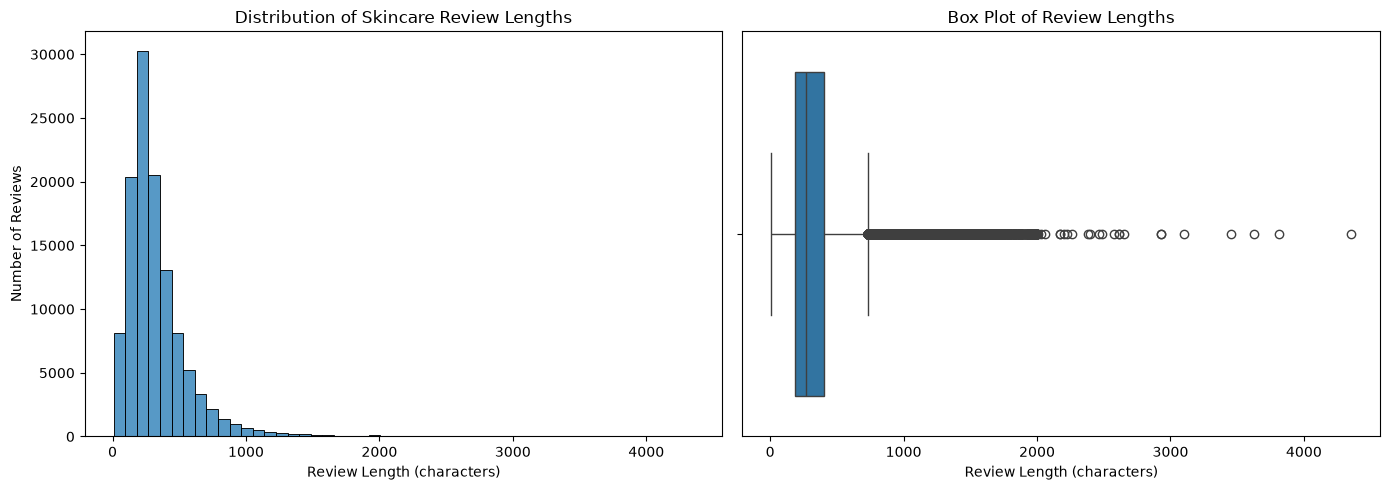

In [24]:
# STEP 16: Visualize Review Length

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(
    data=df,
    x="review_length_chars",
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Distribution of Skincare Review Lengths")
axes[0].set_xlabel("Review Length (characters)")
axes[0].set_ylabel("Number of Reviews")

# Box plot
sns.boxplot(
    data=df,
    x="review_length_chars",
    ax=axes[1]
)
axes[1].set_title("Box Plot of Review Lengths")
axes[1].set_xlabel("Review Length (characters)")

plt.tight_layout()
plt.show()

In [25]:
# STEP 17: Inspect Potential Outliers

outlier_columns = [
    col for col in [
        "review_text",
        "rating",
        "brand_name",
        "review_length_chars"
    ]
    if col in df.columns
]

outlier_examples = (
    df.loc[df["length_outlier"], outlier_columns]
      .sort_values("review_length_chars", ascending=False)
      .head(10)
)

display(outlier_examples)

,review_text,rating,brand_name,review_length_chars
65844,I have suffered with acne since I was in ninth...,5,CLINIQUE,4353
11327,"Personally, I have extremely fair (to the poin...",4,Peter Thomas Roth,3811
18704,First of all I would like to mention to all th...,5,Peter Thomas Roth,3625
38038,My skin responded visibly much better in the w...,4,Algenist,3452
64174,"Alright. Let me first start by saying, I joine...",5,CLINIQUE,3098
72374,I just want to address a couple issues I had r...,2,Drunk Elephant,2931
55497,"Any wrinkle filler, plumper, or firming produc...",5,Peter Thomas Roth,2928
30911,"I was unsure about spending the money on this,...",5,St. Tropez,2652
32208,You’ll hesitate to purchase this product but b...,5,Murad,2618
4287,"I wanted to get some strong retinol, but didn’...",4,Peter Thomas Roth,2612


In [26]:
# STEP 18: Text Preprocessing

import re

if "review_text" not in df.columns:
    raise KeyError("review_text column not found.")

# Create a separate cleaned-text feature
df["review_text_clean"] = (
    df["review_text"]
    .astype("string")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Convert empty strings into missing values
df["review_text_clean"] = df["review_text_clean"].replace(
    "", pd.NA
)

print("Original review text:")
display(df["review_text"].head(5))

print("\nCleaned review text:")
display(df["review_text_clean"].head(5))

print("\nMissing cleaned reviews:",
      df["review_text_clean"].isna().sum())

Original review text:


0    These are the only pimple patches I’ve used th...
1    One of my ingrown hair turned inflamed and sor...
2    I have tried 10 different acne/blemish patches...
3    Love these for my mid-size breakouts, specifyi...
4    Best so far - though still not particularly ef...
Name: review_text, dtype: string


Cleaned review text:


0    These are the only pimple patches I’ve used th...
1    One of my ingrown hair turned inflamed and sor...
2    I have tried 10 different acne/blemish patches...
3    Love these for my mid-size breakouts, specifyi...
4    Best so far - though still not particularly ef...
Name: review_text_clean, dtype: string


Missing cleaned reviews: 0


In [27]:
# STEP 19: Inspect Categorical Values

possible_categories = [
    "brand_name",
    "brand",
    "skin_type",
    "skin_tone",
    "hair_color",
    "eye_color",
    "is_recommended"
]

for col in possible_categories:
    if col in df.columns:
        print(f"\nColumn: {col}")
        print("Number of unique values:", df[col].nunique(dropna=True))
        display(df[col].value_counts(dropna=False).head(15))


Column: brand_name
Number of unique values: 79


brand_name
Peter Thomas Roth     7869
Dr. Jart+             5353
SEPHORA COLLECTION    4134
Supergoop!            4124
Murad                 3359
CLINIQUE              3311
Skinfix               3270
Dermalogica           3197
KORA Organics         3191
St. Tropez            3025
WASO                  2957
The INKEY List        2500
First Aid Beauty      2454
Shiseido              2428
Kiehl's Since 1851    2379
Name: count, dtype: Int64


Column: skin_type
Number of unique values: 4


skin_type
combination    59277
dry            20174
normal         14667
oily           13133
<NA>            8886
Name: count, dtype: Int64


Column: skin_tone
Number of unique values: 13


...

hair_color
brown       44265
blonde      23015
black       21521
<NA>        19731
auburn       3375
red          2850
brunette      819
gray          561
Name: count, dtype: Int64


Column: eye_color
Number of unique values: 6


eye_color
brown    54312
blue     18688
<NA>     16439
hazel    13109
green    12982
Grey       513
gray        94
Name: count, dtype: Int64


Column: is_recommended
Number of unique values: 2


is_recommended
1.0    88322
0.0    16012
NaN    11803
Name: count, dtype: int64

In [28]:
# STEP 20: Standardize Selected Categorical Fields

category_columns = [
    "skin_type",
    "skin_tone",
    "hair_color",
    "eye_color"
]

for col in category_columns:
    if col in df.columns:
        df[col] = (
            df[col]
            .astype("string")
            .str.strip()
            .str.casefold()
        )

print("Selected categorical fields standardized.")

for col in category_columns:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts(dropna=False).head(10))

Selected categorical fields standardized.

skin_type:
skin_type
combination    59277
dry            20174
normal         14667
oily           13133
<NA>            8886
Name: count, dtype: Int64

skin_tone:
skin_tone
light          29346
fair           22448
lightmedium    21332
<NA>           15233
medium          7982
mediumtan       6646
fairlight       6083
tan             3765
deep            2366
rich             663
Name: count, dtype: Int64

hair_color:
hair_color
brown       44265
blonde      23015
black       21521
<NA>        19731
auburn       3375
red          2850
brunette      819
gray          561
Name: count, dtype: Int64

eye_color:
eye_color
brown    54312
blue     18688
<NA>     16439
hazel    13109
green    12982
grey       513
gray        94
Name: count, dtype: Int64


In [29]:
# STEP 21: Check Text Preprocessing Results

print("Dataset shape:", df.shape)

print("\nOriginal review text missing:",
      df["review_text"].isna().sum())

print("Cleaned review text missing:",
      df["review_text_clean"].isna().sum())

print("\nSample of cleaned records:")

columns_to_show = [
    col for col in [
        "review_text",
        "review_text_clean",
        "rating",
        "review_length_chars"
    ]
    if col in df.columns
]

display(df[columns_to_show].head(10))

Dataset shape: (116137, 22)

Original review text missing: 0
Cleaned review text missing: 0

Sample of cleaned records:


,review_text,review_text_clean,rating,review_length_chars
0,These are the only pimple patches I’ve used th...,These are the only pimple patches I’ve used th...,5,80
1,One of my ingrown hair turned inflamed and sor...,One of my ingrown hair turned inflamed and sor...,4,264
2,I have tried 10 different acne/blemish patches...,I have tried 10 different acne/blemish patches...,5,1066
3,"Love these for my mid-size breakouts, specifyi...","Love these for my mid-size breakouts, specifyi...",4,123
4,Best so far - though still not particularly ef...,Best so far - though still not particularly ef...,4,127
5,Not worth it. They arent effective and you can...,Not worth it. They arent effective and you can...,1,77
6,I purchased these originally because I love Dr...,I purchased these originally because I love Dr...,5,571
7,I will be the first to say that the price on t...,I will be the first to say that the price on t...,5,955
8,Both my husband (!) and I have used the dark s...,Both my husband (!) and I have used the dark s...,5,596
9,I wish I had read the reviews before purchasin...,I wish I had read the reviews before purchasin...,2,448


In [30]:
# STEP 22: Final Data Validation

print("========== FINAL DATA VALIDATION ==========")

print("Original dataset shape:", raw_df.shape)
print("Cleaned dataset shape:", df.shape)

print("\nMissing review text:",
      df["review_text"].isna().sum())

print("Blank review text:",
      df["review_text"].astype("string")
        .str.strip().eq("").fillna(False).sum())

print("Exact duplicate rows:", df.duplicated().sum())

if "rating" in df.columns:
    print("Missing ratings:", df["rating"].isna().sum())
    print("Invalid ratings:",
          (~df["rating"].between(1, 5)).sum())

# Automatically verify important conditions
assert df["review_text"].notna().all()
assert df["review_text"].astype("string").str.strip().ne("").all()
assert df["rating"].between(1, 5).all()
assert not df.duplicated().any()

print("\nAll core validation checks passed!")

========== FINAL DATA VALIDATION ==========
Original dataset shape: (116262, 19)
Cleaned dataset shape: (116137, 22)

Missing review text: 0
Blank review text: 0
Exact duplicate rows: 0
Missing ratings: 0
Invalid ratings: 0

All core validation checks passed!


In [31]:
# STEP 23: Save Cleaned Dataset and Audit Reports

from pathlib import Path

# Save outputs beside your original CSV
output_dir = file_path.parent / "week3_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
cleaned_file = output_dir / "cleaned_skincare_reviews.csv"
df.to_csv(cleaned_file, index=False)

# Save final missing-value report
final_missing_report = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

final_missing_report.to_csv(
    output_dir / "final_missing_value_report.csv"
)

# Save final data-quality summary
final_summary = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Original columns",
        "Final rows",
        "Final columns",
        "Rows removed overall",
        "Exact duplicate rows remaining",
        "Missing review text remaining",
        "Invalid ratings remaining"
    ],
    "Value": [
        raw_df.shape[0],
        raw_df.shape[1],
        df.shape[0],
        df.shape[1],
        raw_df.shape[0] - df.shape[0],
        int(df.duplicated().sum()),
        int(df["review_text"].isna().sum()),
        int((~df["rating"].between(1, 5)).sum())
    ]
})

final_summary.to_csv(
    output_dir / "final_data_quality_summary.csv",
    index=False
)

print("Files saved successfully!")
print("Output folder:", output_dir)
print("Cleaned dataset:", cleaned_file)
display(final_summary)

Files saved successfully!
Output folder: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week3_outputs
Cleaned dataset: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week3_outputs\cleaned_skincare_reviews.csv


,Metric,Value
0,Original rows,116262
1,Original columns,19
2,Final rows,116137
3,Final columns,22
4,Rows removed overall,125
5,Exact duplicate rows remaining,0
6,Missing review text remaining,0
7,Invalid ratings remaining,0


In [32]:
# STEP 24: Create Cleaning Log

import json
import pandas as pd
import numpy as np
from datetime import datetime

cleaning_log = {
    "project": "Customer Sentiment Analysis of Skincare Product Reviews",
    "task": "Week 3 - Data Cleaning and Preprocessing",
    "input_file": file_path.name,
    "execution_time": datetime.now().isoformat(timespec="seconds"),
    "python_pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "original_rows": int(raw_df.shape[0]),
    "original_columns": int(raw_df.shape[1]),
    "final_rows": int(df.shape[0]),
    "final_columns": int(df.shape[1]),
    "rows_removed_overall": int(raw_df.shape[0] - df.shape[0]),
    "duplicates_remaining": int(df.duplicated().sum()),
    "missing_review_text_remaining": int(df["review_text"].isna().sum()),
    "cleaned_output_file": "cleaned_skincare_reviews.csv",
    "cleaning_actions": [
        "Standardized column names",
        "Trimmed text whitespace",
        "Converted blank strings to missing values",
        "Removed unusable review text",
        "Checked and removed exact duplicates",
        "Validated ratings against the 1-5 scale",
        "Flagged review-length outliers for investigation",
        "Created a normalized review-text feature",
        "Standardized selected categorical fields",
        "Validated and exported the final dataset"
    ]
}

log_file = output_dir / "cleaning_log.json"

with open(log_file, "w", encoding="utf-8") as f:
    json.dump(cleaning_log, f, indent=4)

print("Cleaning log saved to:", log_file)
print(json.dumps(cleaning_log, indent=4))

Cleaning log saved to: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week3_outputs\cleaning_log.json
{
    "project": "Customer Sentiment Analysis of Skincare Product Reviews",
    "task": "Week 3 - Data Cleaning and Preprocessing",
    "input_file": "reviews_500-750.csv",
    "execution_time": "2026-10-18T17:47:05",
    "python_pandas_version": "3.0.6",
    "numpy_version": "2.3.4",
    "original_rows": 116262,
    "original_columns": 19,
    "final_rows": 116137,
    "final_columns": 22,
    "rows_removed_overall": 125,
    "duplicates_remaining": 0,
    "missing_review_text_remaining": 0,
    "cleaned_output_file": "cleaned_skincare_reviews.csv",
    "cleaning_actions": [
        "Standardized column names",
        "Trimmed text whitespace",
        "Converted blank strings to missing values",
        "Removed unusable review text",
        "Checked and removed exact duplicates",
        "Validated ratings against the 1-5 scale",
        "Flagged review-length outliers for investigat

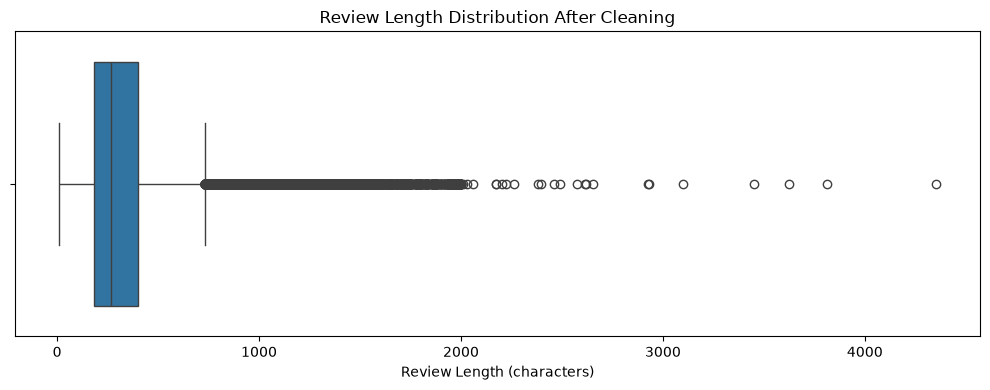

Box plot saved to: C:\Users\ARYAN KATAKDHOND\Downloads\archive\week3_outputs\review_length_boxplot.png


In [33]:
# STEP 25: Save Review-Length Box Plot

plt.figure(figsize=(10, 4))

sns.boxplot(x=df["review_length_chars"])

plt.title("Review Length Distribution After Cleaning")
plt.xlabel("Review Length (characters)")
plt.tight_layout()

chart_file = output_dir / "review_length_boxplot.png"
plt.savefig(chart_file, dpi=300, bbox_inches="tight")
plt.show()

print("Box plot saved to:", chart_file)

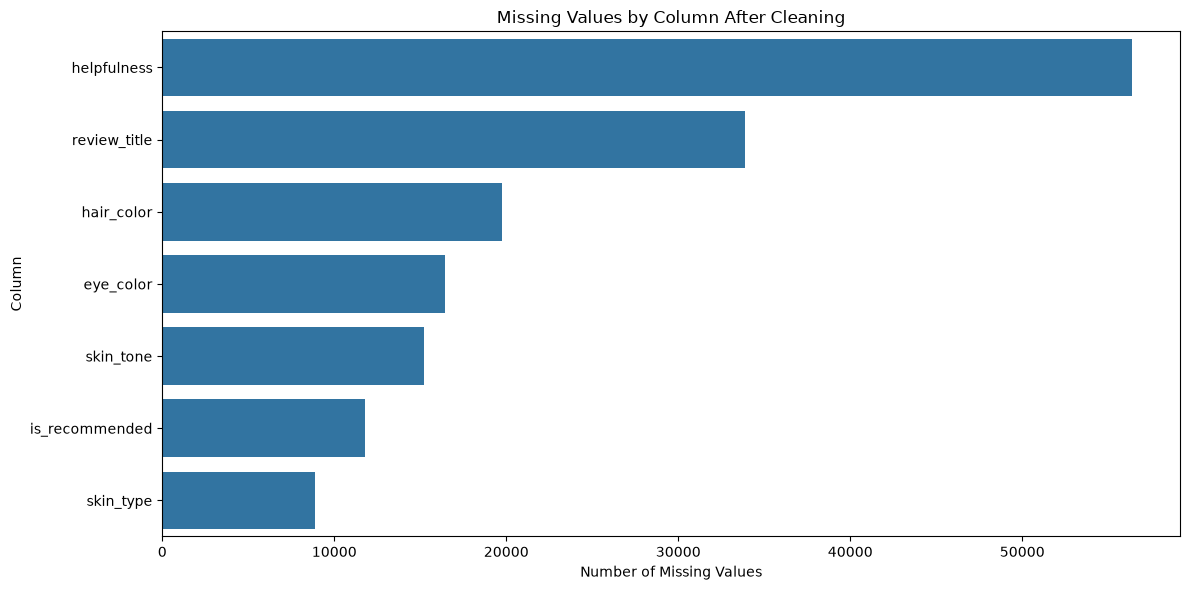

In [34]:
# STEP 26: Visualize Remaining Missing Values

missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

plt.figure(figsize=(12, 6))

if len(missing_counts) > 0:
    sns.barplot(
        x=missing_counts.values,
        y=missing_counts.index
    )
    plt.title("Missing Values by Column After Cleaning")
    plt.xlabel("Number of Missing Values")
    plt.ylabel("Column")
else:
    plt.text(0.5, 0.5, "No missing values found",
             ha="center", va="center")
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    output_dir / "missing_values_after_cleaning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

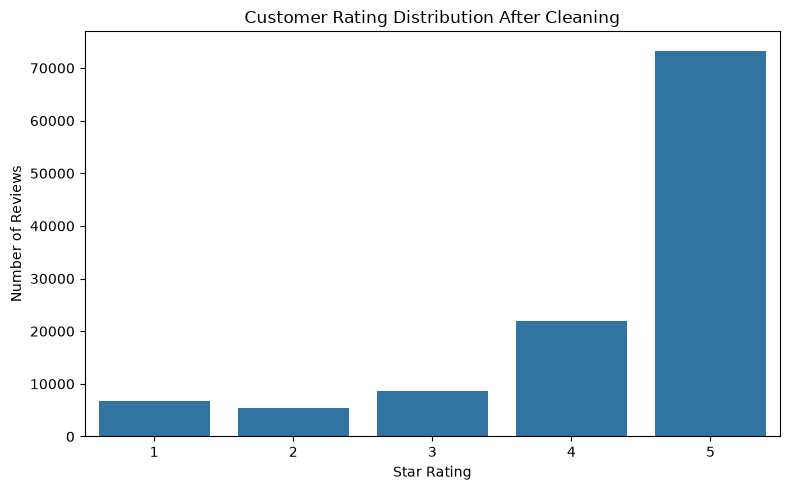

,Number of Reviews
Rating,
1,6702
2,5473
3,8662
4,21997
5,73303


In [35]:
# STEP 27: Rating Distribution

rating_counts = (
    df["rating"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_counts.index.astype(str),
    y=rating_counts.values
)

plt.title("Customer Rating Distribution After Cleaning")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig(
    output_dir / "rating_distribution_after_cleaning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(
    rating_counts.rename_axis("Rating")
    .to_frame("Number of Reviews")
)

In [36]:
# STEP 28: Before-and-After Comparison

comparison = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Total columns",
        "Exact duplicate rows",
        "Missing review text",
        "Missing ratings"
    ],
    "Before Cleaning": [
        len(raw_df),
        raw_df.shape[1],
        int(raw_df.duplicated().sum()),
        int((
            raw_df["review_text"].isna()
            | raw_df["review_text"].astype("string")
              .str.strip().eq("").fillna(False)
        ).sum()),
        int(raw_df["rating"].isna().sum())
    ],
    "After Cleaning": [
        len(df),
        df.shape[1],
        int(df.duplicated().sum()),
        int((
            df["review_text"].isna()
            | df["review_text"].astype("string")
              .str.strip().eq("").fillna(False)
        ).sum()),
        int(df["rating"].isna().sum())
    ]
})

display(comparison)

comparison.to_csv(
    output_dir / "before_after_comparison.csv",
    index=False
)

print("Before-and-after comparison saved successfully!")

,Metric,Before Cleaning,After Cleaning
0,Total rows,116262,116137
1,Total columns,19,22
2,Exact duplicate rows,0,0
3,Missing review text,125,0
4,Missing ratings,0,0


Before-and-after comparison saved successfully!
